# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [5]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
385,0.023546,0.050680,-0.019140,0.049415,-0.063487,-0.061125,0.004460,-0.039493,-0.025953,-0.013504,219.0
300,0.016281,-0.044642,0.073552,NaN,-0.004321,-0.013527,-0.013948,-0.001116,0.042897,0.044485,275.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
42,-0.060003,0.050680,-0.010517,-0.014863,-0.049727,-0.023547,-0.058127,0.015858,-0.009919,-0.034215,61.0
311,0.096197,-0.044642,NaN,-0.057313,0.045213,0.060690,-0.021311,0.036154,0.012551,0.023775,180.0
200,0.056239,-0.044642,-0.057941,-0.007977,0.052093,0.049103,0.056003,-0.021412,-0.028323,0.044485,158.0
271,0.038076,0.050680,0.008883,0.042529,-0.042848,-0.021042,-0.039719,-0.002592,-0.018114,0.007207,127.0
76,-0.030942,0.050680,NaN,0.070072,-0.126781,-0.106845,-0.054446,-0.047981,-0.030748,0.015491,170.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [6]:
# Conteo de valores faltantes por columna
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [7]:
# Guardamos la columna original
data['bmi_original'] = data['bmi'].copy()

# Aplicamos imputador simple
imputer_simple = SimpleImputer(strategy='mean')
data['bmi_simple'] = imputer_simple.fit_transform(data[['bmi']])

# mostramos
data[['bmi_original', 'bmi_simple']].sample(5)

,bmi_original,bmi_simple
232,0.000261,0.000261
48,-0.041774,-0.041774
388,-0.024529,-0.024529
220,-0.039618,-0.039618
351,-0.040696,-0.040696


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [8]:
# Inicializamos el imputador KNN con 2 vecinos
knn_imputer = KNNImputer(n_neighbors=2)

# Aplicamos la transformación de las columnas "bmi" y "bp"
imputed_values = knn_imputer.fit_transform(data[['bmi', 'bp']])

# Asignamos los resultados a nuevas columnas
data['bmi_knn'] = imputed_values[:, 0]
data['bp_knn'] = imputed_values[:, 1]

# Comparamos los resultados de las filas que originalmente tenían nulos en 'bmi'
filas_nulas_bmi = data[data['bmi_original'].isnull()]
filas_nulas_bmi[['bmi_original', 'bmi_simple', 'bmi_knn', 'bp', 'bp_knn']].head()

,bmi_original,bmi_simple,bmi_knn,bp,bp_knn
9,NaN,-0.000205,-0.011595,-0.033213,-0.033213
30,NaN,-0.000205,-0.000205,NaN,0.000465
39,NaN,-0.000205,-0.000205,NaN,0.000465
55,NaN,-0.000205,0.012656,-0.036656,-0.036656
70,NaN,-0.000205,-0.004050,-0.012556,-0.012556


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

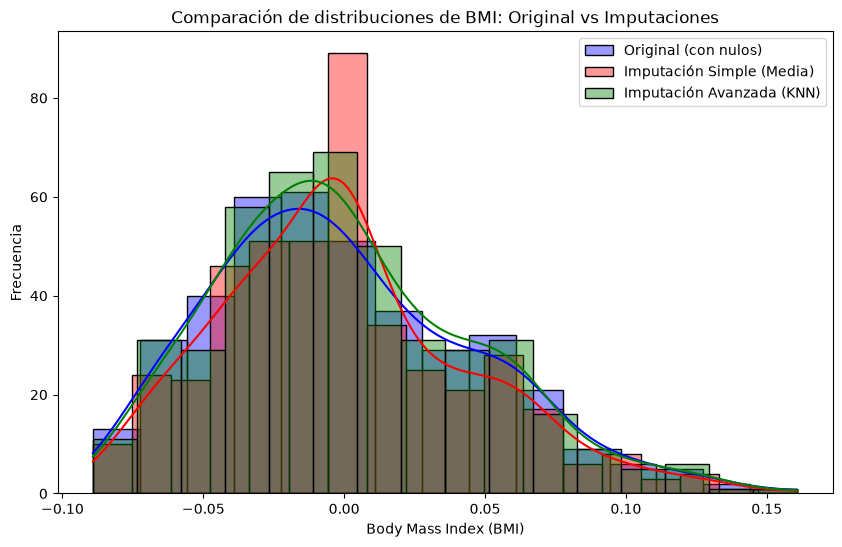

In [9]:
# Configuración del tamaño
plt.figure(figsize=(10, 6))

# Generación de histogramas
sns.histplot(data['bmi_original'], color='blue', label='Original (con nulos)', kde=True, alpha=0.4)
sns.histplot(data['bmi_simple'], color='red', label='Imputación Simple (Media)', kde=True, alpha=0.4)
sns.histplot(data['bmi_knn'], color='green', label='Imputación Avanzada (KNN)', kde=True, alpha=0.4)

# Etiquetas y título
plt.title('Comparación de distribuciones de BMI: Original vs Imputaciones')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()